# 03 · Models: SHCNN, geology-aware ViT, SHVCNN

Thin driver over `geompm.models` / `geompm.training`. Bugs fixed relative to the original notebook (details in the module docstrings):

* **SHVCNN trained only its last layer**: `forward` called the global `vit_model`, not `self.vit_model`.
* **Double sigmoid**: models returned probabilities into `binary_cross_entropy_with_logits`. The SHCNN loss was stuck at 1.7580. Models now return logits.
* **GeoLoss**: softmax over the batch compared with one scalar; λ was learnable; a, b never optimised. It is now a per-sample prior with fixed λ, and a, b are in the optimiser.
* **g**: was a random 16384-vector sliced to `[:768]` (≈0.008 per entry). It is now a per-sample / per-token value from the g map.
* **w**: was one random 32×32 map shared by all samples. It is now a patch aligned with each input.
* **Attention bias M**: `ones @ (w*w) @ ones` was constant across patches, so softmax cancelled it. It is now per-token w_i·w_j (or a learned MLP).

Full experiments (leave-one-deposit-out, all baselines/ablations) run from the CLI:
```
python scripts/run_experiment.py configs/shvcnn.json
```

In [1]:
import os, sys
from pathlib import Path
# run from the repo root so relative data paths resolve
if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

C:\Users\Asus\OneDrive\Desktop\Rare_Earth_Elements


In [2]:
import torch
from geompm.config import ModelConfig, ExperimentConfig
from geompm.models import MODEL_NAMES, build_model, count_parameters
from geompm.geology import GeoLoss

# Sanity check on random tensors: shapes and gradient flow to every parameter
B, C, P = 4, 35, 32
x, w, gp, gc = torch.randn(B, C, P, P), torch.rand(B, 1, P, P), torch.rand(B, 1, P, P), torch.rand(B)
for name in MODEL_NAMES:
    m = build_model(ModelConfig(name=name), C)
    loss, _ = GeoLoss(0.1)(m(x, w, gp, gc), torch.randint(0, 2, (B,)).float(), w[:, 0, 16, 16])
    loss.backward()
    dead = [n for n, p in m.named_parameters() if p.grad is None and not n.endswith("alpha")]
    print(f"{name:8s} params={count_parameters(m):>8,d}  params without grad: {dead}")

cnn      params=2,126,113  params without grad: []
shcnn    params=2,126,113  params without grad: []
vit      params= 510,861  params without grad: []
geovit   params= 510,861  params without grad: []


cnn_vit  params= 524,333  params without grad: []
shvcnn   params= 524,333  params without grad: []


## Short training run on Curnamona (all deposits; the map shows fit, not predictive skill)

In [3]:
import numpy as np, matplotlib.pyplot as plt
from geompm.data.curnamona import load_or_prepare
from geompm.training.experiment import run_full

gg = load_or_prepare()
maps = {}
for name in ["shcnn", "shvcnn"]:
    cfg = ExperimentConfig.from_dict({"name": name, "model": {"name": name}, "train": {"epochs": 15}})
    out = run_full(gg, cfg, verbose=False)
    maps[name] = out["prob"]
    print(name, "final loss", round(out["info"]["history"][-1]["loss"], 4), "| train success-rate AUC", round(out["train_success_rate_auc"], 3))

shcnn final loss 0.0771 | train success-rate AUC 0.892


shvcnn final loss 0.0956 | train success-rate AUC 0.895


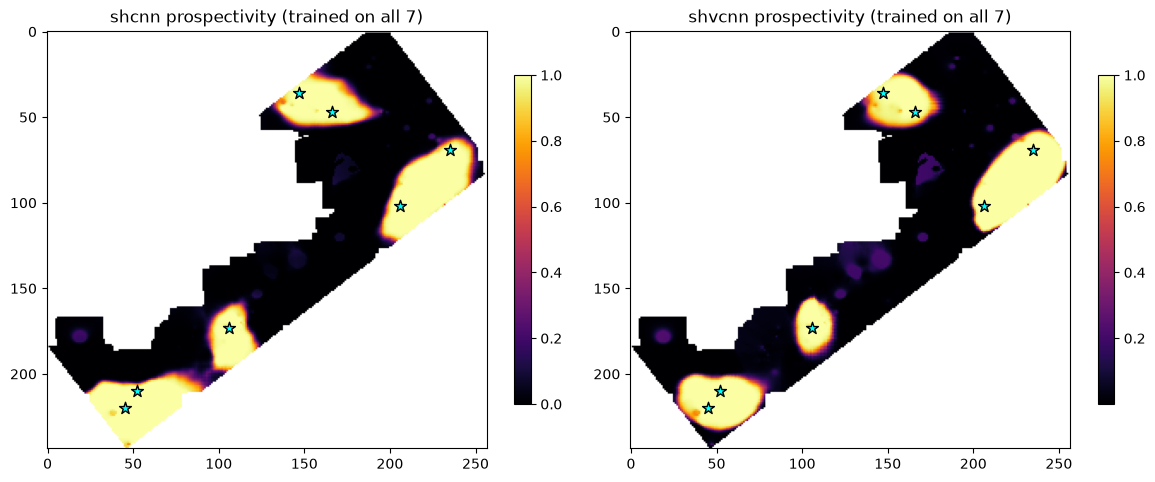

In [4]:
fig, axes = plt.subplots(1, len(maps), figsize=(12, 5))
for ax, (name, prob) in zip(axes, maps.items()):
    im = ax.imshow(prob, cmap="inferno"); ax.set_title(f"{name} prospectivity (trained on all 7)")
    ax.scatter(gg.deposits_rc[:, 1], gg.deposits_rc[:, 0], marker="*", c="cyan", s=80, edgecolors="k")
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

## Leave-one-deposit-out evaluation
`area_rank` = fraction of the study area scoring at least as high as the held-out deposit (lower is better; random ≈ 0.5). Run the full grid from the CLI. Each config writes `experiments/results/<name>/results.json`:

```
for c in cnn shcnn vit geovit cnn_vit shvcnn shvcnn_learned_affinity shvcnn_hard_only cnn_soft_only; do
    python scripts/run_experiment.py configs/$c.json --mode lodo
done
```